# Podstawy sztucznej inteligencji: PyTorch i jeden neuron

Neuron, stratę i spadek gradientu już znacie. Dziś robimy to samo w **PyTorch**, bibliotece do budowy i uczenia sieci neuronowych. Pracujemy z **jednym neuronem**, żeby dobrze poznać narzędzie; sieci z warstwą ukrytą na następnych zajęciach.

Przykład przewodni: czy student zaliczy przedmiot?

| Część | Temat | Czas |
|---|---|---|
| 1 | Neuron w PyTorch (suwaki) | 5 min |
| 2 | Spadek gradientu i autograd (suwaki) | 10 min |
| 3 | Neuron uczy się, kto zda + mini-batch | 15 min |
| 4 | Tensory i `nn.Linear` (własny kod) | 15 min |
| 5 | Twoja pętla uczenia od zera (własny kod) | 25 min |

W częściach 1–3 są dwie ścieżki:
- 🎚️ **Suwaki**: przesuwasz suwak po prawej stronie komórki, wykres zmienia się sam.
- 💻 **Kod**: zmieniasz liczby oznaczone `# ← zmień` i uruchamiasz komórkę (Shift+Enter).

W częściach 4–5 **piszesz kod sam** w komórkach `# Twój kod`.

**Jak pracujemy**
- Najpierw zapisz kopię: *Plik → Zapisz kopię na Dysku*.
- Potem *Środowisko wykonawcze → Uruchom wszystko* (Ctrl+F9). Pierwsze uruchomienie trwa ok. minuty.
- Najpierw **przewiduj**, potem sprawdź. Odpowiedzi wpisuj krótko w komórkach „Odpowiedzi”.

In [1]:
#@title ⚙️ Przygotowanie (uruchom najpierw) { display-mode: "form" }
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import ListedColormap
from IPython.display import HTML, display
import torch
from torch import nn

plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.titleweight": "bold"})
plt.rcParams["animation.embed_limit"] = 50
ZIELONY, CZERWONY, NIEBIESKI, SZARY = "#00B050", "#C00000", "#0070C0", "#7F7F7F"
TLO = ListedColormap(["#FDECEC", "#E8F5E9"])      # tło: czerwone = „nie zda”, zielone = „zda”

# Studenci z poprzednich lat: obecność [%], kolokwium [pkt], czy zaliczył (1 = tak, 0 = nie)
STUDENCI = pd.DataFrame([
    ("Ania", 90, 70, 1), ("Bartek", 50, 30, 0), ("Celina", 95, 85, 1), ("Darek", 20, 15, 0),
    ("Ewa", 75, 55, 1), ("Filip", 60, 45, 0), ("Hania", 80, 50, 1), ("Igor", 65, 70, 1),
    ("Julia", 100, 40, 1), ("Kuba", 55, 80, 1), ("Lena", 85, 90, 1), ("Marek", 70, 60, 1),
    ("Natalia", 45, 90, 1), ("Oskar", 95, 35, 1), ("Paweł", 30, 50, 0), ("Róża", 40, 60, 0),
    ("Szymon", 70, 35, 0), ("Tola", 10, 40, 0), ("Urszula", 55, 45, 0), ("Wiktor", 35, 25, 0),
    ("Zosia", 80, 20, 0), ("Adam", 25, 75, 0), ("Basia", 42, 64, 0), ("Cezary", 62, 40, 0)],
    columns=["imię", "obecność", "kolokwium", "zaliczył"])
XS = STUDENCI[["obecność", "kolokwium"]].values / 100     # cechy w skali 0–1
YS = STUDENCI["zaliczył"].values
GOSIA = (70, 52)                                           # nowa studentka: nie wiemy, czy zda

def rysuj_studentow(ax, legenda=True):
    """Rysuje studentów jako punkty: niebieskie kółka zaliczyli, czerwone krzyżyki nie. Gosia to „?”."""
    for y, kolor, znak, opis in [(1, NIEBIESKI, "o", "zaliczył"), (0, CZERWONY, "X", "nie zaliczył")]:
        s = STUDENCI[STUDENCI["zaliczył"] == y]
        ax.scatter(s["obecność"], s["kolokwium"], c=kolor, marker=znak, s=90,
                   edgecolors="black", linewidths=0.6, zorder=3, label=opis)
    ax.scatter(*GOSIA, c="white", marker="o", s=160, edgecolors="black", zorder=3)
    ax.annotate("?", GOSIA, ha="center", va="center", fontsize=11, fontweight="bold", zorder=4)
    ax.annotate("Gosia", GOSIA, xytext=(9, 6), textcoords="offset points", fontsize=9)
    ax.set_xlim(0, 105); ax.set_ylim(0, 105); ax.set_aspect("equal")
    ax.set_xlabel("obecność [%]"); ax.set_ylabel("kolokwium [pkt]"); ax.grid(alpha=0.3)
    if legenda:
        ax.legend(loc="lower right", fontsize=9)

def rysuj_granice(ax, w1, w2, b, kolor="black", styl="-", tlo=True):
    """Granica neuronu: w1·x1 + w2·x2 + b = 0 (x w skali 0–1, rysujemy w procentach)."""
    g = np.linspace(0, 1.05, 300)
    gx, gy = np.meshgrid(g, g)
    if tlo:
        ax.contourf(gx * 100, gy * 100, (w1 * gx + w2 * gy + b > 0).astype(int),
                    levels=[-0.5, 0.5, 1.5], cmap=TLO, alpha=0.9)
    ax.contour(gx * 100, gy * 100, w1 * gx + w2 * gy + b, levels=[0], colors=kolor,
               linestyles=styl, linewidths=2.5)

def odmien(n, jeden, kilka, wiele):
    """Polska odmiana: 1 krok, 2 kroki, 5 kroków."""
    if n == 1:
        return f"{n} {jeden}"
    if n % 10 in (2, 3, 4) and n % 100 not in (12, 13, 14):
        return f"{n} {kilka}"
    return f"{n} {wiele}"

print("Gotowe. PyTorch w wersji", torch.__version__, "· przejdź do części 1.")

Gotowe. PyTorch w wersji 2.14.1+cpu · przejdź do części 1.


---
# Część 1. Neuron: wagi i bias

Neuron dostaje kilka liczb (**cechy**), mnoży każdą przez jej **wagę**, sumuje i dodaje **bias**:

$$ z = w_1 x_1 + w_2 x_2 + w_3 x_3 + b $$

Potem porównuje z progiem: jeśli $z > 0$, odpowiada „zda”, w przeciwnym razie „nie zda”.

Cechy to obecność, wynik kolokwium i oddane zadania. Obecność i kolokwium zapisujemy w skali 0–1 (90% → 0,9; 70 pkt → 0,7). Zadania: 1 = oddał, 0 = nie oddał.

### Zadanie 1
1. Ustawienie startowe to Ania: obecność 90%, kolokwium 70 pkt, zadania oddane, wagi 2, 3, 1, bias −4. Ile wynosi z? Czy Ania zda?
2. Ustaw Bartka: obecność 50%, kolokwium 30 pkt, zadania oddane. Ile wynosi z?
3. Wróć do Ani. Zmniejszaj wynik kolokwium. Przy ilu punktach Ania przestaje zdawać?
4. Zmień bias z −4 na −2. Czy teraz łatwiej, czy trudniej zdać? Co robi bias?

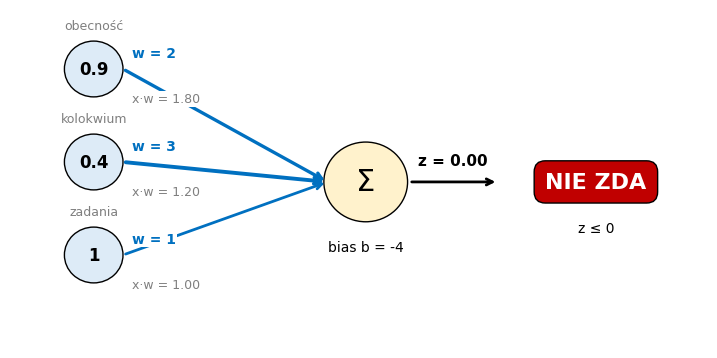

z = 0.9·2 + 0.4·3 + 1·1 + (-4) = 0.00 → NIE ZDA


In [17]:
#@title 🎚️ Neuron z suwakami { run: "auto", display-mode: "form" }
obecnosc = 90 #@param {type:"slider", min:0, max:100, step:5}
kolokwium = 40 #@param {type:"slider", min:0, max:100, step:5}
zadania = "oddane" #@param ["oddane", "nieoddane"]
w1 = 2 #@param {type:"slider", min:-5, max:5, step:0.5}
w2 = 3 #@param {type:"slider", min:-5, max:5, step:0.5}
w3 = 1 #@param {type:"slider", min:-5, max:5, step:0.5}
b = -4 #@param {type:"slider", min:-8, max:4, step:0.5}

x = [obecnosc / 100, kolokwium / 100, 1 if zadania == "oddane" else 0]
w = [w1, w2, w3]
iloczyny = [xi * wi for xi, wi in zip(x, w)]
z = round(sum(iloczyny) + b, 10)        # zaokrąglenie usuwa błędy typu 0,30000000000000004
zda = z > 0

# Rysunek neuronu: wejścia → wagi → suma Σ → próg → odpowiedź
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.set_xlim(0, 10); ax.set_ylim(0, 5.1); ax.axis("off")
nazwy = ["obecność", "kolokwium", "zadania"]
for i, (n, xi, wi, p) in enumerate(zip(nazwy, x, w, iloczyny)):
    yy = 4.2 - i * 1.4
    ax.add_patch(plt.Circle((1.2, yy), 0.42, color="#DDEBF7", ec="black"))
    ax.text(1.2, yy, f"{xi:g}", ha="center", va="center", fontsize=12, fontweight="bold")
    ax.text(1.2, yy + 0.55, n, ha="center", va="bottom", fontsize=9, color=SZARY)
    ax.annotate("", xy=(4.55, 2.5), xytext=(1.62, yy), arrowprops=dict(arrowstyle="->", lw=1.6 + abs(wi) * 0.4,
                color=NIEBIESKI if wi >= 0 else CZERWONY))
    ax.text(1.75, yy + 0.18, f"w = {wi:g}", fontsize=10, ha="left",
            color=NIEBIESKI if wi >= 0 else CZERWONY, fontweight="bold",
            bbox=dict(fc="white", ec="none", pad=1), zorder=5)
    ax.text(1.75, yy - 0.5, f"x·w = {p:.2f}", fontsize=9, ha="left", color=SZARY,
            bbox=dict(fc="white", ec="none", pad=1), zorder=5)
ax.add_patch(plt.Circle((5.1, 2.5), 0.6, color="#FFF2CC", ec="black"))
ax.text(5.1, 2.5, "Σ", ha="center", va="center", fontsize=22)
ax.text(5.1, 1.45, f"bias b = {b:g}", ha="center", fontsize=10)
ax.annotate("", xy=(7.0, 2.5), xytext=(5.72, 2.5), arrowprops=dict(arrowstyle="->", lw=2))
ax.text(6.35, 2.75, f"z = {z:.2f}", ha="center", fontsize=11, fontweight="bold")
ax.text(8.4, 2.5, "ZDA" if zda else "NIE ZDA", ha="center", va="center", fontsize=16, fontweight="bold",
        color="white", bbox=dict(boxstyle="round,pad=0.5", fc=ZIELONY if zda else CZERWONY))
ax.text(8.4, 1.75, "z > 0" if zda else "z ≤ 0", ha="center", fontsize=10)
plt.show()
print("z =", " + ".join(f"{xi:g}·{wi:g}" for xi, wi in zip(x, w)), f"+ ({b:g}) = {z:.2f}",
      "→ ZDA" if zda else "→ NIE ZDA")

### 💻 Kod: neuron to mnożenie i dodawanie
Ten sam rachunek w zwykłym Pythonie, a potem w **PyTorch** (biblioteka do sieci neuronowych). W PyTorch liczby trzymamy w **tensorach** (`torch.tensor`), czyli tablicach liczb. Znak `@` mnoży parami i sumuje (iloczyn skalarny).

In [14]:
# Zwykły Python
x1, x2, x3 = 0.9, 0.7, 1      # ← zmień: obecność, kolokwium, zadania
w1, w2, w3 = 2, 3, 1          # ← zmień: wagi
b = -4                        # ← zmień: bias

z = w1 * x1 + w2 * x2 + w3 * x3 + b
print("z =", round(z, 2), "→ zda" if z > 0 else "→ nie zda")

# To samo w PyTorch
x = torch.tensor([x1, x2, x3], dtype=torch.float32)
w = torch.tensor([w1, w2, w3], dtype=torch.float32)
z = x @ w + b                 # @ = pomnóż parami i dodaj
print("z (PyTorch) =", round(z.item(), 2))

# Gotowy neuron w PyTorch: nn.Linear(3, 1) = 3 wejścia, 1 wyjście, czyli 3 wagi i 1 bias.
# Na początku wagi są losowe: model jeszcze nic nie umie. Uczenie to poprawianie tych liczb.
neuron = nn.Linear(768, 768)      # ← zmień: spróbuj nn.Linear(768, 768), taki rozmiar ma warstwa w GPT-2
print("liczba parametrów nn.Linear:", sum(p.numel() for p in neuron.parameters()))

z = 0.9 → zda
z (PyTorch) = 0.9
liczba parametrów nn.Linear: 590592


**Odpowiedzi (1):**
1. z wynosi 0.9. Tak, Ania zda.
2. z wynosi -1.1. Bartek nie zda
3. Ania przestaje zdawać przy 40 punktów (z = 0.0)
4. Zmniejszenie biasu sprawia, że łatwiej zdać. Bias "ciągnie" końcowy wynik w dół - przesuwa granicę decyzyjną.

---
# Część 2. Spadek gradientu

Uczenie to szukanie wag z najmniejszą **stratą** (jedna liczba mówiąca, jak bardzo model się myli). Duże modele mają miliony wag, więc nie da się sprawdzić wszystkich kombinacji. Znamy tylko stratę i jej **pochodną** (nachylenie) w bieżącym punkcie.

- Pochodna $L'(w) > 0$: strata rośnie, gdy zwiększamy $w$. Żeby ją zmniejszyć, zmniejszamy $w$.
- Pochodna $L'(w) < 0$: strata maleje, gdy zwiększamy $w$. Zwiększamy $w$.

Stąd reguła spadku gradientu:

$$ w \leftarrow w - \eta \cdot L'(w) $$

Minus, bo idziemy w stronę **przeciwną** do pochodnej, czyli tam, gdzie strata maleje. $\eta$ (eta) to **krok uczenia** (ang. *learning rate*). Przy wielu wagach pochodne po każdej wadze tworzą **gradient**, a reguła działa dla każdej wagi osobno.

Tu model ma **jedną wagę**, a strata to $L(w) = 0{,}5\,(w - 2)^2 + 0{,}3$, więc $L'(w) = w - 2$. Najlepsza waga to $w = 2$. Algorytm tego nie wie: zna tylko pochodną w punkcie, w którym jest.

### Zadanie 2
1. Ustawienie startowe: start $w = -0{,}5$, $\eta = 0{,}4$. Popatrz na tabelę pierwszych kroków pod wykresem. Dlaczego kroki są coraz krótsze, choć $\eta$ się nie zmienia?
2. Ustaw $\eta = 0{,}05$. Ile kroków trzeba, żeby dojść do $w \approx 1{,}9$?
3. Ustaw $\eta = 1{,}0$. Co się dzieje?
4. Ustaw $\eta = 1{,}8$, a potem $\eta = 2{,}2$. Co widzisz?
5. Zacznij z drugiej strony: start $w = 5$. Czy algorytm też trafia do $w = 2$? Dlaczego?

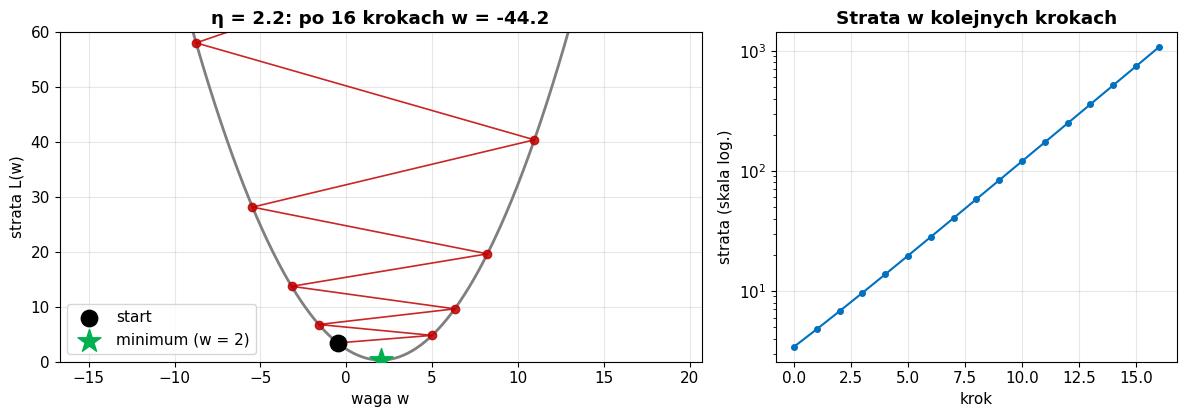

krok,w,strata L(w),pochodna L'(w),zmiana −η·L'(w)
0,-0.500000,3.420000,-2.500000,5.500000
1,5.000000,4.800000,3.000000,-6.600000
2,-1.600000,6.780000,-3.600000,7.920000
3,6.320000,9.630000,4.320000,-9.500000
4,-3.180000,13.740000,-5.180000,11.400000
5,8.220000,19.650000,6.220000,-13.690000


⚠️ Waga oddala się od minimum: krok uczenia jest za duży!


In [24]:
#@title 🎚️ Spadek gradientu z suwakami { run: "auto", display-mode: "form" }
start = -0.5 #@param {type:"slider", min:-3, max:6, step:0.5}
eta = 2.2 #@param {type:"slider", min:0.05, max:2.5, step:0.05}
kroki = 16 #@param {type:"slider", min:1, max:100, step:1}

L = lambda w: 0.5 * (w - 2) ** 2 + 0.3       # strata
pochodna = lambda w: w - 2                    # pochodna straty L'(w)

ws = [start]
for _ in range(kroki):
    ws.append(ws[-1] - eta * pochodna(ws[-1]))   # reguła spadku gradientu
ws = np.array(ws)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.6, 1]})
lo, hi = min(-3.5, ws.min() - 0.5), max(7.5, ws.max() + 0.5)
lo, hi = max(lo, -15), min(hi, 19)
xx = np.linspace(lo, hi, 400)
a1.plot(xx, L(xx), color=SZARY, lw=2)
widoczne = (ws > lo) & (ws < hi)
a1.plot(ws[widoczne], L(ws[widoczne]), "o-", color=CZERWONY, ms=6, lw=1.2, alpha=0.85)
a1.scatter([ws[0]], [L(ws[0])], s=140, color="black", zorder=4, label="start")
a1.scatter([2], [0.3], marker="*", s=300, color=ZIELONY, zorder=4, label="minimum (w = 2)")
a1.set_ylim(0, min(L(xx).max(), 60)); a1.set_xlabel("waga w"); a1.set_ylabel("strata L(w)")
a1.set_title(f"η = {eta:g}: po {odmien(kroki, 'kroku', 'krokach', 'krokach')} w = {ws[-1]:.3g}")
a1.legend(); a1.grid(alpha=0.3)
a2.plot(range(len(ws)), L(ws), "o-", color=NIEBIESKI, ms=4)
a2.set_yscale("log"); a2.set_xlabel("krok"); a2.set_ylabel("strata (skala log.)")
a2.set_title("Strata w kolejnych krokach"); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

n = min(kroki, 6)                                # tabela pierwszych kroków
tab = pd.DataFrame({"krok": range(n), "w": ws[:n].round(2), "strata L(w)": L(ws[:n]).round(2),
                    "pochodna L'(w)": pochodna(ws[:n]).round(2),
                    "zmiana −η·L'(w)": (-eta * pochodna(ws[:n])).round(2)})
display(tab.style.hide(axis="index"))
if abs(ws[-1] - 2) > abs(ws[0] - 2):
    print("⚠️ Waga oddala się od minimum: krok uczenia jest za duży!")

### 💻 Kod: spadek gradientu w kilku linijkach
Pochodną `w − 2` wpisaliśmy ręcznie. Sieć neuronowa ma miliony wag i bardzo długi wzór, więc nikt nie liczy tam pochodnych ręcznie. PyTorch robi to sam (**autograd**):
- `requires_grad=True`: „śledź tę liczbę, będę potrzebować pochodnej”,
- `strata.backward()`: „policz pochodną” (dla sieci nazywa się to propagacją wsteczną),
- wynik jest w `w.grad`.

In [5]:
w = -0.5        # ← zmień: waga startowa
eta = 0.4       # ← zmień: krok uczenia

for krok in range(10):
    pochodna = w - 2                   # pochodna straty L(w) = 0,5·(w − 2)² + 0,3
    w = w - eta * pochodna             # krok przeciw pochodnej
    print(f"krok {krok + 1:2d}:  w = {w:.3f}   strata = {0.5 * (w - 2) ** 2 + 0.3:.3f}")

# To samo, ale pochodną liczy PyTorch
w = torch.tensor(-0.5, requires_grad=True)
strata = 0.5 * (w - 2) ** 2 + 0.3
strata.backward()
print("\nautograd: pochodna w punkcie w = -0,5 to", w.grad.item(), " (ze wzoru: w − 2 = -2,5)")

krok  1:  w = 0.500   strata = 1.425
krok  2:  w = 1.100   strata = 0.705
krok  3:  w = 1.460   strata = 0.446
krok  4:  w = 1.676   strata = 0.352
krok  5:  w = 1.806   strata = 0.319
krok  6:  w = 1.883   strata = 0.307
krok  7:  w = 1.930   strata = 0.302
krok  8:  w = 1.958   strata = 0.301
krok  9:  w = 1.975   strata = 0.300
krok 10:  w = 1.985   strata = 0.300

autograd: pochodna w punkcie w = -0,5 to -2.5  (ze wzoru: w − 2 = -2,5)


**Odpowiedzi (2):**
1. Kroki sa coraz krótsze, bo im blizej celu (waga 2), tym wykres jest bardziej plaski i pochodna jest mniejsza. Mniejsza pochodna oznacza mniejszy ruch w każdym kroku
2. Przy kroku uczenia 0.05 i starcie od -0.5 potrzeba 63 kroków, żeby dojść do około 1.9
3. Przy kroku uczenia 1,0 algorytm trafia prosto w cel w = 2 już po pierwszym kroku
4. Przy 1,8 waga przeskakuje na drugą stronę celu i skacze w kółko, ale powoli się zbliża do 2. Przy 2,2 skacze coraz mocniej i oddala się od celu, więc błąd rośnie
5. Tak, algorytm też trafi do w = 2. Z każdego miejsca ruch w dół prowadzi do tego samego minimum

---
# Część 3. Neuron uczy się, kto zda

Mamy 24 studentów z poprzednich lat: **obecność**, wynik **kolokwium** i czy zaliczyli (niebieskie kółka: tak, czerwone krzyżyki: nie). Gosia (białe „?”) to nowa studentka. Neuron z dwiema wagami i biasem ma sam znaleźć prostą, która oddziela tych, co zdali, od tych, co nie zdali.

Neuron podaje **prawdopodobieństwo** „zda”: wynik $z$ przepuszczamy przez **sigmoidę** $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ (liczba od 0 do 1, $z = 0$ daje 0,5). Strata to **MSE**: średnia z $(\sigma(z) - y)^2$.

Neuron startuje z losowych wag. W każdej **epoce** (jedno przejście przez wszystkich 24 studentów):
1. neuron liczy prawdopodobieństwo $\sigma(z)$ dla każdego studenta,
2. liczymy stratę MSE,
3. PyTorch liczy gradient (`backward()`, jak w części 2),
4. każda waga robi krok $w \leftarrow w - \eta \cdot$ pochodna.

Animacja pokazuje, jak granica decyzyjna przesuwa się w czasie uczenia. Kliknij ▶ pod wykresem.

### Zadanie 3
1. Przy ustawieniu startowym ($\eta = 2$, 500 epok): w której epoce neuron pierwszy raz ocenia dobrze wszystkich 24 studentów?
2. Podziel nauczone wagi i bias przez $w_2$ (wypisane pod animacją). Jaką prostą znalazł neuron? Która cecha ma większą wagę?
3. Jakie prawdopodobieństwo zdania daje neuron Gosi? Dlaczego nie 99%?
4. Ustaw $\eta = 0{,}5$, a potem $\eta = 20$. Jak zmienia się epoka, w której neuron ma 24 z 24?

In [26]:
#@title 🎚️ Neuron uczy się granicy decyzyjnej { run: "auto", display-mode: "form" }
eta = 20 #@param [0.5, 1, 2, 5, 10, 20] {type:"raw"}
epoki = 500 #@param {type:"slider", min:100, max:3000, step:100}

X = torch.tensor(XS, dtype=torch.float32)
Y = torch.tensor(YS, dtype=torch.float32).reshape(-1, 1)
torch.manual_seed(1)                      # ten sam losowy start dla wszystkich
neuron = nn.Linear(2, 1)                  # 2 wagi (obecność, kolokwium) i bias
opt = torch.optim.SGD(neuron.parameters(), lr=eta)   # SGD = spadek gradientu

historia, pierwsza_24 = [], None
for e in range(epoki):
    p = torch.sigmoid(neuron(X))          # 1. prawdopodobieństwo „zda”
    strata = ((p - Y) ** 2).mean()        # 2. strata MSE
    opt.zero_grad()                       #    (wyczyść gradienty z poprzedniej epoki)
    strata.backward()                     # 3. gradient
    opt.step()                            # 4. krok dla wszystkich wag
    w1, w2 = neuron.weight[0].tolist(); b = neuron.bias.item()
    ok = int(((neuron(X) > 0).float() == Y).sum())
    if ok == len(YS) and pierwsza_24 is None:
        pierwsza_24 = e + 1
    historia.append((e + 1, w1, w2, b, strata.item(), ok))

# Animacja: ok. 40 klatek, gęściej na początku uczenia
klatki = sorted(set(np.geomspace(1, epoki, 40).astype(int) - 1))
fig, ax = plt.subplots(figsize=(5.8, 5.8))
fig.subplots_adjust(left=0.13, right=0.97, bottom=0.1, top=0.88)
def klatka(i):
    ax.clear()
    e, w1, w2, b, s, ok = historia[i]
    rysuj_granice(ax, w1, w2, b)
    rysuj_studentow(ax, legenda=False)
    ax.set_title(f"epoka {e}: poprawnie {ok} z {len(YS)}, strata {s:.3f}\n"
                 f"w1 = {w1:.2f}  w2 = {w2:.2f}  b = {b:.2f}", fontsize=10,
                 color=ZIELONY if ok == len(YS) else "black")
anim = animation.FuncAnimation(fig, klatka, frames=klatki, interval=250)
plt.close(fig)
display(HTML(anim.to_jshtml()))

e, w1, w2, b, s, ok = historia[-1]
print(f"Po {epoki} epokach: w1 = {w1:.2f}, w2 = {w2:.2f}, b = {b:.2f}, poprawnie {ok} z {len(YS)}, strata {s:.3f}.")
print(f"Po podzieleniu przez w2: {w1 / w2:.2f} · obecność + 1 · kolokwium + ({b / w2:.2f})")
print(f"Pierwszy raz 24 z 24 w epoce {pierwsza_24}." if pierwsza_24 else "Neuron jeszcze się myli: dodaj epok.")
p = torch.sigmoid(neuron(torch.tensor([[GOSIA[0] / 100, GOSIA[1] / 100]]))).item()
print(f"Gosia: neuron mówi „{p:.0%}, że zda”.")

Po 500 epokach: w1 = 16.49, w2 = 15.50, b = -18.83, poprawnie 24 z 24, strata 0.005.
Po podzieleniu przez w2: 1.06 · obecność + 1 · kolokwium + (-1.21)
Pierwszy raz 24 z 24 w epoce 66.
Gosia: neuron mówi „68%, że zda”.


### 💻 Kod: pętla treningowa
Tak wygląda pętla treningowa w PyTorch. **Ma zawsze ten sam kształt**: tak samo uczy się neuron z dwiema wagami, sieć neuronowa i model językowy z miliardami wag.

| linijka | co robi |
|---|---|
| `nn.Linear(2, 1)` | neuron: 2 wagi i bias |
| `torch.optim.SGD(..., lr=eta)` | spadek gradientu z krokiem uczenia η |
| `opt.zero_grad()` | wyczyść gradienty z poprzedniej epoki (PyTorch je sumuje) |
| `strata.backward()` | policz gradient (autograd) |
| `opt.step()` | zrób krok dla wszystkich wag |

In [7]:
torch.manual_seed(1)
neuron = nn.Linear(2, 1)
opt = torch.optim.SGD(neuron.parameters(), lr=2)        # ← zmień: krok uczenia

for epoka in range(500):                                # ← zmień: liczba epok
    p = torch.sigmoid(neuron(X))                        # 1. model przewiduje
    strata = ((p - Y) ** 2).mean()                      # 2. strata MSE
    opt.zero_grad()                                     # 3. czyścimy stare gradienty
    strata.backward()                                   # 4. liczymy nowe gradienty
    opt.step()                                          # 5. krok
    if epoka % 100 == 0:
        print(f"epoka {epoka:3d}   strata = {strata.item():.4f}")

epoka   0   strata = 0.2437
epoka 100   strata = 0.1180
epoka 200   strata = 0.0856
epoka 300   strata = 0.0685
epoka 400   strata = 0.0572


**Odpowiedzi (3):**
1. Kod poprawnie ocenia wszystkich studentów w 53 epoce.
2. Największą wagę ma obecność. Neuron znalazł prostą 1.09 x obecność + 1 x kolokwium - 1.23
3. Neuron daje Gosi 59% szansy na zdanie. Nie daje 99%, bo Gosia leży blisko granicy, gdzie jedni studenci zdają, a inni nie. Istnieją proste, które stawiają Gosię poniżej progu zdania, równocześnie klasyfikując poprawnie resztę studentów
4. Eta = 0.5, epoka 192. Dla eta = 20, epoka 73. Dla eta = 2 pierwsza prosta, która klasyfikuje wszystkich studentów poprawnie została znaleziona szybciej.

### 3b. Mini-batch w PyTorch

Do tej pory neuron robił **jeden krok na epokę**, liczony ze wszystkich 24 studentów naraz (pełny spadek gradientu). Dane można podzielić na **porcje** (*mini-batch*) i robić krok po każdej porcji. W PyTorch porcje tworzy `DataLoader`:

```python
loader = DataLoader(TensorDataset(X, Y), batch_size=4, shuffle=True)
for epoka in range(epoki):
    for xb, yb in loader:      # kolejna porcja: 4 studentów
        ...                    # strata z porcji, backward, step: jeden krok
```

- `TensorDataset(X, Y)` łączy cechy i odpowiedzi w pary (student, czy zdał),
- `batch_size` to liczba przykładów w porcji, więc kroków na epokę jest $\lceil 24 / \text{batch\_size} \rceil$,
- `shuffle=True` tasuje studentów przed każdą epoką, więc porcje są za każdym razem inne.

### Zadanie 3b
1. Uruchom komórkę. Ile kroków na epokę robi neuron przy każdym `batch_size`? Który wariant to pełny spadek gradientu, a który SGD?
2. W której epoce neuron pierwszy raz ma 24 z 24? Ile to **kroków** łącznie? Co jest „szybsze”: liczone w epokach czy w krokach?
3. Zmień `eta` na 20. Który `batch_size` na tym traci? Dlaczego?

batch_size = 24: 1 krok na epokę, 24 z 24 w epoce 66 (= 66 kroków)
batch_size =  8: 3 kroki na epokę, 24 z 24 w epoce 8 (= 24 kroki)
batch_size =  4: 6 kroków na epokę, 24 z 24 w epoce 11 (= 66 kroków)
batch_size =  1: 24 kroki na epokę, 24 z 24 w epoce 43 (= 1032 kroki)


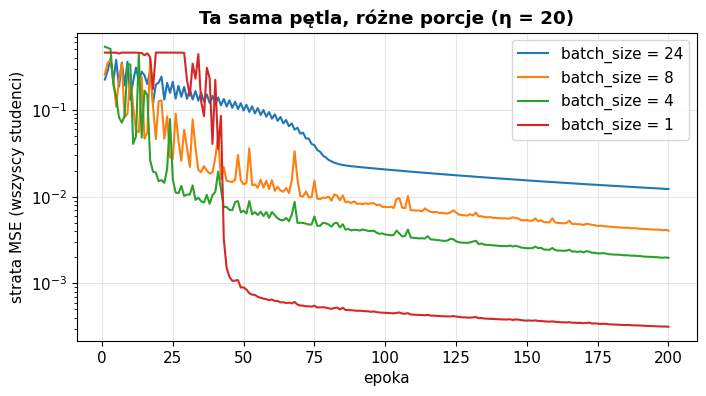

In [28]:
from torch.utils.data import TensorDataset, DataLoader

eta = 20                                   # ← zmień: krok uczenia
rozmiary = [24, 8, 4, 1]                  # ← zmień: batch_size (24 = cały zbiór)

fig, ax = plt.subplots(figsize=(8, 4))
for batch_size in rozmiary:
    torch.manual_seed(1)                  # ten sam start wag i to samo tasowanie
    neuron = nn.Linear(2, 1)
    opt = torch.optim.SGD(neuron.parameters(), lr=eta)
    loader = DataLoader(TensorDataset(X, Y), batch_size=batch_size, shuffle=True)

    straty, pierwsza_24 = [], None
    for epoka in range(200):
        for xb, yb in loader:                                   # kolejna porcja studentów
            strata = ((torch.sigmoid(neuron(xb)) - yb) ** 2).mean()
            opt.zero_grad(); strata.backward(); opt.step()      # krok po każdej porcji
        with torch.no_grad():                                   # pomiar na wszystkich 24 studentach
            straty.append(((torch.sigmoid(neuron(X)) - Y) ** 2).mean().item())
            ok = int(((neuron(X) > 0).float() == Y).sum())
        if ok == len(YS) and pierwsza_24 is None:
            pierwsza_24 = epoka + 1

    kroki = len(loader)
    opis = (f"24 z 24 w epoce {pierwsza_24} (= {odmien(pierwsza_24 * kroki, 'krok', 'kroki', 'kroków')})" if pierwsza_24
            else "jeszcze nie 24 z 24")
    print(f"batch_size = {batch_size:2d}: {odmien(kroki, 'krok', 'kroki', 'kroków')} na epokę, {opis}")
    ax.plot(range(1, 201), straty, label=f"batch_size = {batch_size}")

ax.set_yscale("log"); ax.set_xlabel("epoka"); ax.set_ylabel("strata MSE (wszyscy studenci)")
ax.set_title(f"Ta sama pętla, różne porcje (η = {eta})"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

**Odpowiedzi (3b):**
1. Dla batch_size 24, 8, 4, 1 neuron robi odpowiednio 1, 3, 6 i 24 kroki (SDG)
2. Dla batch_size 24, 8 i 4 liczba kroków jest porównywalna (47-66). Dla batch_size = 1 liczba kroków wzrasta natomiast do 192. W krokach najszybszy jest duży batch size, mało kroków. W epokach najszybszy jest mały batch size.
3. Najbardziej traci na tym batch_size = 1, bo jeden przykład daje bardzo nierówny kierunek zmiany wag i przy dużym kroku model mocno się rozbiega

---
# Część 4. Tensory i `nn.Linear`

Od tej części **piszesz kod sam**. Komórka z przykładem jest gotowa; zadania robisz w komórce `# Twój kod`.

**Tensor** to tablica liczb jak w NumPy: **wiersz = przykład, kolumna = cecha**. Sieci liczą na liczbach z kropką (`float32`), dlatego przy przenoszeniu danych z NumPy podajemy `dtype=torch.float32`.

In [29]:
X_k = torch.tensor([[0.9, 0.7, 1.0],      # Ania: obecność, kolokwium, zadania
                    [0.5, 0.3, 1.0],      # Bartek
                    [0.2, 0.15, 0.0]])    # Darek
print(X_k)
print("kształt:", X_k.shape, "   typ:", X_k.dtype)
print("kolokwium wszystkich:", X_k[:, 1])
print("Bartek:", X_k[1])

w = torch.tensor([2.0, 3.0, 1.0])
print("z = X @ w - 4:", X_k @ w - 4)       # neuron dla trzech studentów naraz

tensor([[0.9000, 0.7000, 1.0000],
        [0.5000, 0.3000, 1.0000],
        [0.2000, 0.1500, 0.0000]])
kształt: torch.Size([3, 3])    typ: torch.float32
kolokwium wszystkich: tensor([0.7000, 0.3000, 0.1500])
Bartek: tensor([0.5000, 0.3000, 1.0000])
z = X @ w - 4: tensor([ 0.9000, -1.1000, -3.1500])


### Zadanie 4

1. Utwórz tensor `T` z **5 przykładami i 3 cechami** (np. `torch.rand(5, 3)`). Wypisz kształt, trzecią cechę wszystkich przykładów i cały drugi przykład.
2. Policz `T.mean(dim=0)` i `T.mean(dim=1)`. Jaki kształt ma każdy wynik? Która to średnia każdej **cechy**, a która każdego **przykładu**?
3. Utwórz `neuron = nn.Linear(3, 1)`. Jakie kształty mają `neuron.weight` i `neuron.bias`? Przepuść przez niego `X_k`. Jaki kształt ma wynik?
4. Ustaw wagi neuronu ręcznie na $(2, 3, 1)$ i bias na $-4$ (jak w części 1) i sprawdź, czy dla Ani wychodzi $z = 0{,}9$. Wskazówka:
```python
with torch.no_grad():                           # zmieniamy wagi ręcznie, bez śledzenia gradientów
    neuron.weight[:] = torch.tensor([[2.0, 3.0, 1.0]])
    neuron.bias[:] = torch.tensor([-4.0])
```
5. Podaj do neuronu tensor `torch.tensor([[1, 1, 1]])` (liczby całkowite, bez kropek). Co się dzieje? Jak to naprawić?

In [33]:
# 1
T = torch.rand(5, 3)
print("T:\n", T)
print("Kształt T:", T.shape)
print("Trzecia cecha wszystkich przykładów:", T[:, 2])
print("Cały drugi przykład:", T[1])

# 2
mean_dim0 = T.mean(dim=0)
mean_dim1 = T.mean(dim=1)
print("\nT.mean(dim=0):", mean_dim0, "kształt:", mean_dim0.shape)  # średnia każdej cechy (3 wartości)
print("T.mean(dim=1):", mean_dim1, "kształt:", mean_dim1.shape)  # średnia każdego przykładu (5 wartości)

# 3
neuron = nn.Linear(3, 1)
print("\nKształt weight:", neuron.weight.shape)  # (1, 3)
print("Kształt bias:", neuron.bias.shape)      # (1,)
wynik_Xk = neuron(X_k)
print("Wynik neuron(X_k):\n", wynik_Xk, "kształt:", wynik_Xk.shape)  # (3, 1)

# 4
with torch.no_grad():
    neuron.weight[:] = torch.tensor([[2.0, 3.0, 1.0]])
    neuron.bias[:] = torch.tensor([-4.0])

z_wszyscy = neuron(X_k)
print("\nz dla [Ania, Bartek, Darek]:\n", z_wszyscy)
print("z dla Ani:", z_wszyscy[0].item())

# 5
try:
    print(neuron(torch.tensor([[1, 1, 1]])))
except RuntimeError as e:
    print("\nBłąd przy tensorze int:", e)

print("Poprawka (float32):", neuron(torch.tensor([[1, 1, 1]], dtype=torch.float32)).item())

T:
 tensor([[0.1320, 0.3074, 0.6341],
        [0.4901, 0.8964, 0.4556],
        [0.6323, 0.3489, 0.4017],
        [0.0223, 0.1689, 0.2939],
        [0.5185, 0.6977, 0.8000]])
Kształt T: torch.Size([5, 3])
Trzecia cecha wszystkich przykładów: tensor([0.6341, 0.4556, 0.4017, 0.2939, 0.8000])
Cały drugi przykład: tensor([0.4901, 0.8964, 0.4556])

T.mean(dim=0): tensor([0.3591, 0.4839, 0.5171]) kształt: torch.Size([3])
T.mean(dim=1): tensor([0.3578, 0.6141, 0.4610, 0.1617, 0.6721]) kształt: torch.Size([5])

Kształt weight: torch.Size([1, 3])
Kształt bias: torch.Size([1])
Wynik neuron(X_k):
 tensor([[0.1609],
        [0.4180],
        [0.3634]], grad_fn=<AddmmBackward0>) kształt: torch.Size([3, 1])

z dla [Ania, Bartek, Darek]:
 tensor([[ 0.9000],
        [-1.1000],
        [-3.1500]], grad_fn=<AddmmBackward0>)
z dla Ani: 0.8999996185302734

Błąd przy tensorze int: mat1 and mat2 must have the same dtype, but got Long and Float
Poprawka (float32): 2.0


---
# Część 5. Twoja pętla uczenia od zera

Teraz piszesz **całe uczenie sam**, wzorując się na komórce „💻 Kod: pętla treningowa” z części 3. Tym razem neuron przewiduje **liczbę** (regresja), więc bez sigmoidy: wyjście to samo $z$, a strata to MSE `nn.MSELoss()`.

Dane mają **dwie cechy** i powstały z wzoru $y = 2x_1 - 3x_2 + 1$ (plus mały szum). Czy neuron sam znajdzie te liczby?

In [11]:
torch.manual_seed(0)
X2 = torch.randn(200, 2)                                          # 200 przykładów, 2 cechy
y2 = 2 * X2[:, 0:1] - 3 * X2[:, 1:2] + 1 + 0.1 * torch.randn(200, 1)
print("X2:", tuple(X2.shape), "  y2:", tuple(y2.shape))

X2: (200, 2)   y2: (200, 1)


### Zadanie 5

1. Utwórz model (2 wejścia, 1 wyjście), stratę `nn.MSELoss()` i optymalizator `torch.optim.SGD` z `lr = 0.1`.
2. Napisz pętlę uczenia na całym zbiorze (100 epok). Zapisuj stratę z każdej epoki do listy i narysuj ją (`plt.plot`, oś y w skali log.: `plt.yscale("log")`).
3. Wypisz nauczone wagi i bias. Czy są bliskie $(2, -3)$ i $1$?
4. Sprawdź `lr` równe `0.01`, `0.5` i `1.5`. Przy którym model nie zdąży się nauczyć w 100 epokach, a przy którym strata rośnie?
5. Zakomentuj `zero_grad()` i naucz od nowa (`lr = 0.1`). Co dzieje się ze stratą i wagami? Dlaczego?
6. Zamień `y2` na `y2[:, 0]` (kształt `(200,)` zamiast `(200, 1)`). Co wypisuje PyTorch i jaki wychodzi model? Dlaczego kształt etykiet musi zgadzać się z kształtem wyjścia modelu?
7. ★ Ucz mini-batchami: `DataLoader(TensorDataset(X2, y2), batch_size=20, shuffle=True)`. Ile kroków na epokę? Ile epok wystarczy?

Wskazówka (szkielet):
```python
model = ...
loss_fn = ...
opt = ...
straty = []
for epoka in range(100):
    strata = loss_fn(model(X2), y2)
    ...                                  # trzy linijki: wyczyść, policz gradienty, krok
    straty.append(strata.item())
```

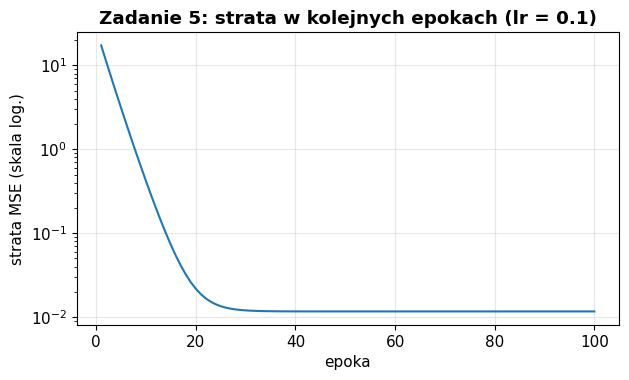

Nauczone wagi: w1 = 1.9972, w2 = -3.0023, bias = 1.0073
lr=0.01 -> strata start: 17.3216, po 100 epokach: 0.4119
lr=0.50 -> strata start: 17.3216, po 100 epokach: 0.0117
lr=1.50 -> strata start: 17.3216, po 100 epokach: nan
Bez zero_grad() po 100 epokach: strata = 2.2173757553100586 wagi = [[1.796012043952942, -1.5949305295944214]] bias = 0.9094377160072327
Z y2[:, 0] (kształt (200,)) strata po 100 epokach: 12.046685218811035


In [34]:
from torch.utils.data import TensorDataset, DataLoader

# 1-3
torch.manual_seed(0)
model = nn.Linear(2, 1)
loss_fn = nn.MSELoss()
opt = torch.optim.SGD(model.parameters(), lr=0.1)

straty = []
for epoka in range(100):
    pred = model(X2)
    strata = loss_fn(pred, y2)
    opt.zero_grad()
    strata.backward()
    opt.step()
    straty.append(strata.item())

plt.figure(figsize=(7, 3.8))
plt.plot(range(1, 101), straty)
plt.yscale("log")
plt.xlabel("epoka")
plt.ylabel("strata MSE (skala log.)")
plt.title("Zadanie 5: strata w kolejnych epokach (lr = 0.1)")
plt.grid(alpha=0.3)
plt.show()

w_ucz = model.weight.detach().numpy().flatten()
b_ucz = model.bias.item()
print(f"Nauczone wagi: w1 = {w_ucz[0]:.4f}, w2 = {w_ucz[1]:.4f}, bias = {b_ucz:.4f}")

# 4
for lr_test in [0.01, 0.5, 1.5]:
    torch.manual_seed(0)
    m = nn.Linear(2, 1)
    o = torch.optim.SGD(m.parameters(), lr=lr_test)
    s_list = []
    for _ in range(100):
        l = loss_fn(m(X2), y2)
        o.zero_grad()
        l.backward()
        o.step()
        s_list.append(l.item())
    print(f"lr={lr_test:4.2f} -> strata start: {s_list[0]:.4f}, po 100 epokach: {s_list[-1]:.4f}")

# 5
torch.manual_seed(0)
m_no_zero = nn.Linear(2, 1)
o_no_zero = torch.optim.SGD(m_no_zero.parameters(), lr=0.1)
for epoka in range(100):
    l = loss_fn(m_no_zero(X2), y2)
    l.backward()     # brak opt.zero_grad() -> gradienty sumują się z poprzednich kroków!
    o_no_zero.step()
print("Bez zero_grad() po 100 epokach: strata =", loss_fn(m_no_zero(X2), y2).item(),
      "wagi =", m_no_zero.weight.detach().tolist(), "bias =", m_no_zero.bias.item())

# 6
y2_1d = y2[:, 0]
torch.manual_seed(0)
m_1d = nn.Linear(2, 1)
o_1d = torch.optim.SGD(m_1d.parameters(), lr=0.1)
for _ in range(100):
    l = loss_fn(m_1d(X2), y2_1d)  # ostrzeżenie o broadcastingu (200, 1) vs (200,)
    o_1d.zero_grad()
    l.backward()
    o_1d.step()
print("Z y2[:, 0] (kształt (200,)) strata po 100 epokach:", loss_fn(m_1d(X2), y2_1d).item())


---
# Podsumowanie

| pojęcie | co to jest | w kodzie |
|---|---|---|
| tensor | tablica liczb: wiersz = przykład, kolumna = cecha | `torch.tensor(..., dtype=torch.float32)` |
| neuron | suma ważona wejść + bias | `nn.Linear(wejścia, 1)` |
| sigmoid | zamienia $z$ na prawdopodobieństwo (0–1) | `torch.sigmoid` |
| strata MSE | średni kwadrat błędu | `nn.MSELoss()`, `((p - y) ** 2).mean()` |
| autograd | PyTorch sam liczy pochodne | `strata.backward()`, `w.grad` |
| optymalizator | robi krok: $w := w - \eta \cdot$ gradient | `torch.optim.SGD(model.parameters(), lr=...)` |
| pętla uczenia | przewiduj → strata → wyczyść → gradient → krok | `zero_grad()`, `backward()`, `step()` |
| mini-batch | krok po każdej porcji danych | `DataLoader(..., batch_size=..., shuffle=True)` |

Odpowiedz krótko (2–3 zdania na pytanie):
1. Co robi `strata.backward()`, a co `opt.step()`? Po co jest `opt.zero_grad()`?
2. Co się dzieje, gdy krok uczenia jest za mały, a co, gdy za duży?
3. Ile kroków na epokę wykona model przy $n$ przykładach i `batch_size` $= B$? Po co `shuffle=True`?
4. Dlaczego etykiety muszą mieć kształt `(n, 1)`, a nie `(n,)`?

**Odpowiedzi (Podsumowanie):**
1. strata.backward() liczy pochodne błędu względem wag, a opt.step() przesuwa wagi na podstawie tych pochodnych. opt.zero_grad() czyści stare pochodne, bo inaczej PyTorch by je do siebie dodawał

2. Za mały krok uczenia sprawia, że model uczy się bardzo powoli. Za duży krok sprawia, że model przeskakuje cel a błąd rośnie zamiast maleć

3. Przy n przykładach i paczce wielkości B w jednej epoce jest n podzielone przez B kroków (zaokrąglone w górę). shuffle=True miesza dane co epokę, żeby paczki były inne i model nie uczył się kolejności przykładów

4. Kształt (n, 1) pasuje do wyjścia neuronu dla n przykładów i zapobiega problemom z automatycznym dopasowywaniem wymiarów podczas liczenia błędu.